# Evaluation Comparison

# 1: Imports

In [2]:
import sys
sys.path.append("..")

import os, json, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
keras = tf.keras
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

from src.config import *
from src.data_utils import load_raw_dataset, prepare

sns.set_theme(style="whitegrid")

# 2: Load the test set into memory

In [3]:
test_ds = prepare(load_raw_dataset(TEST_DIR, shuffle=False), augment=False)
X_test = np.concatenate([x.numpy() for x, _ in test_ds])
y_test = np.concatenate([y.numpy().argmax(axis=1) for _, y in test_ds])
print(X_test.shape, y_test.shape)
print("Per-class counts:", dict(zip(CLASS_NAMES, np.bincount(y_test))))

Found 246 files belonging to 4 classes.
(246, 224, 224, 3) (246,)
Per-class counts: {'glioma': np.int64(80), 'meningioma': np.int64(63), 'no_tumor': np.int64(49), 'pituitary': np.int64(54)}


# 3: Load all four models

In [4]:
MODEL_FILES = {
    "Custom CNN":     "custom_cnn.h5",
    "MobileNetV2":    "MobileNetV2.h5",
    "EfficientNetB0": "EfficientNetB0.h5",
    "ResNet50":       "ResNet50.h5",
}

models = {}
for name, fname in MODEL_FILES.items():
    path = MODELS_DIR / fname
    models[name] = keras.models.load_model(path, compile=False)
    print(f"Loaded {name:15s} {path.stat().st_size / 1e6:7.1f} MB")

Loaded Custom CNN         12.3 MB
Loaded MobileNetV2        26.7 MB
Loaded EfficientNetB0     36.9 MB
Loaded ResNet50          227.5 MB


# 4: Predictions and metrics

In [5]:
probs, preds, rows = {}, {}, []
for name, m in models.items():
    p = m.predict(X_test, batch_size=32, verbose=0)
    probs[name], preds[name] = p, p.argmax(axis=1)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds[name], average="macro", zero_division=0)
    _, _, f1_w, _ = precision_recall_fscore_support(y_test, preds[name], average="weighted", zero_division=0)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, preds[name]),
                 "Precision (macro)": prec, "Recall (macro)": rec,
                 "F1 (macro)": f1, "F1 (weighted)": f1_w})

metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
display(metrics_df)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
Model,,,,,
Custom CNN,0.6626,0.7198,0.6720,0.6587,0.6645
MobileNetV2,0.8333,0.8414,0.8361,0.8307,0.8330
EfficientNetB0,0.6951,0.7772,0.6714,0.6779,0.6766
ResNet50,0.9106,0.9139,0.9047,0.9059,0.9103


# 5: Per-class classification reports

In [6]:
for name in models:
    print(f"\n{'=' * 18} {name} {'=' * 18}")
    print(classification_report(y_test, preds[name], target_names=CLASS_NAMES, digits=3))


================== Custom CNN ==================
              precision    recall  f1-score   support

      glioma      0.912     0.650     0.759        80
  meningioma      0.700     0.444     0.544        63
    no_tumor      0.789     0.612     0.690        49
   pituitary      0.477     0.981     0.642        54

    accuracy                          0.663       246
   macro avg      0.720     0.672     0.659       246
weighted avg      0.738     0.663     0.664       246


================== MobileNetV2 ==================
              precision    recall  f1-score   support

      glioma      0.932     0.850     0.889        80
  meningioma      0.786     0.698     0.739        63
    no_tumor      0.929     0.796     0.857        49
   pituitary      0.720     1.000     0.837        54

    accuracy                          0.833       246
   macro avg      0.841     0.836     0.831       246
weighted avg      0.847     0.833     0.833       246


================== Efficient

# 6: Confusion matrices

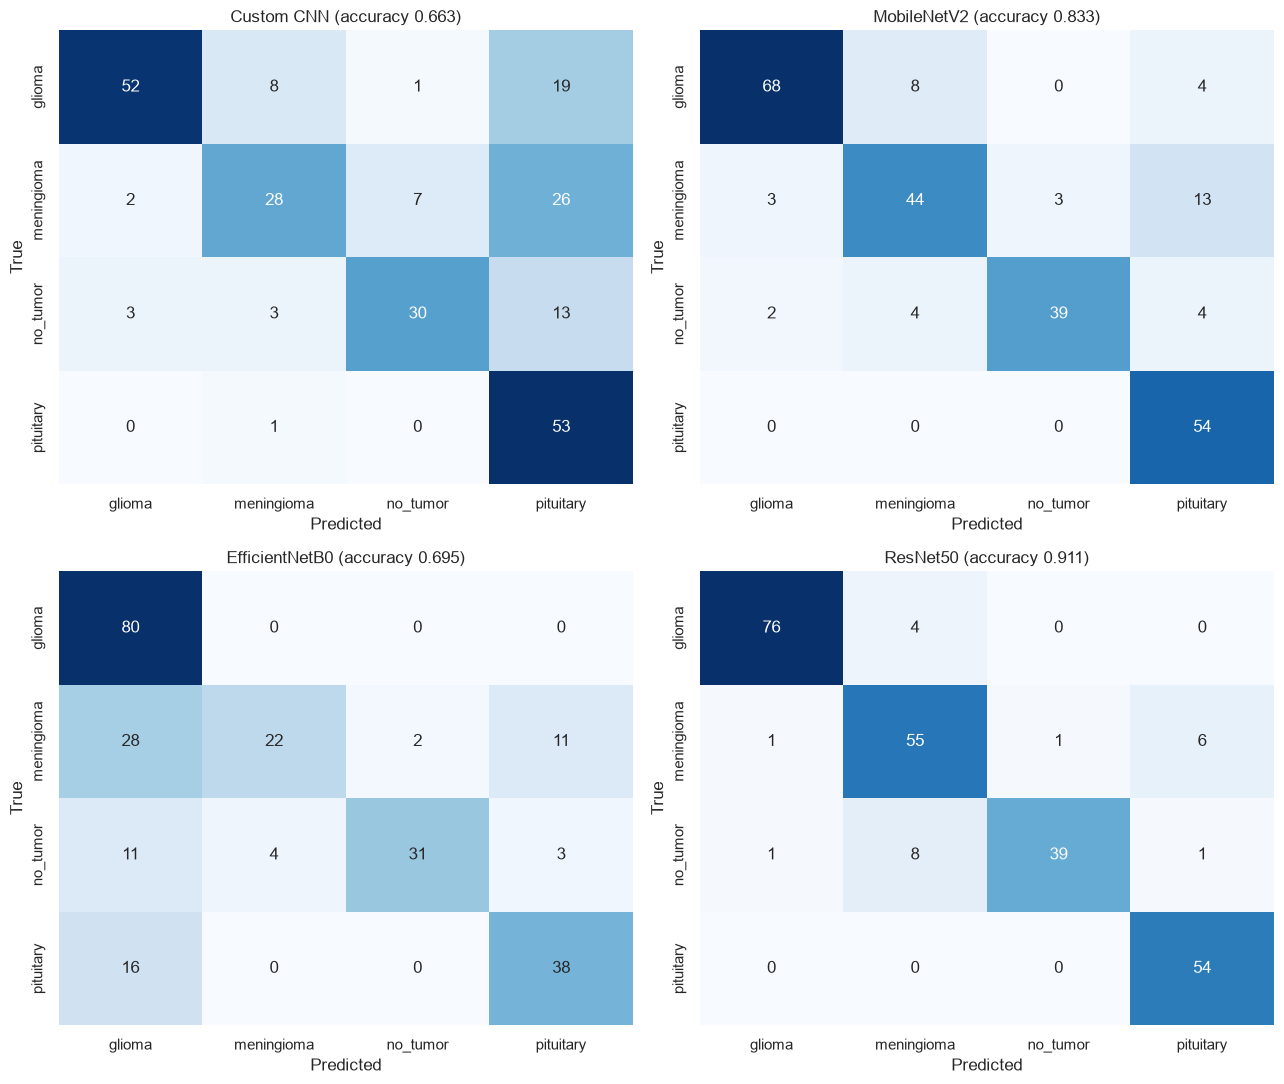

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, name in zip(axes.flat, models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{name} (accuracy {accuracy_score(y_test, preds[name]):.3f})")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_confusion_matrices.png", dpi=150)
plt.show()

# 7: Training history plots (accuracy and loss)

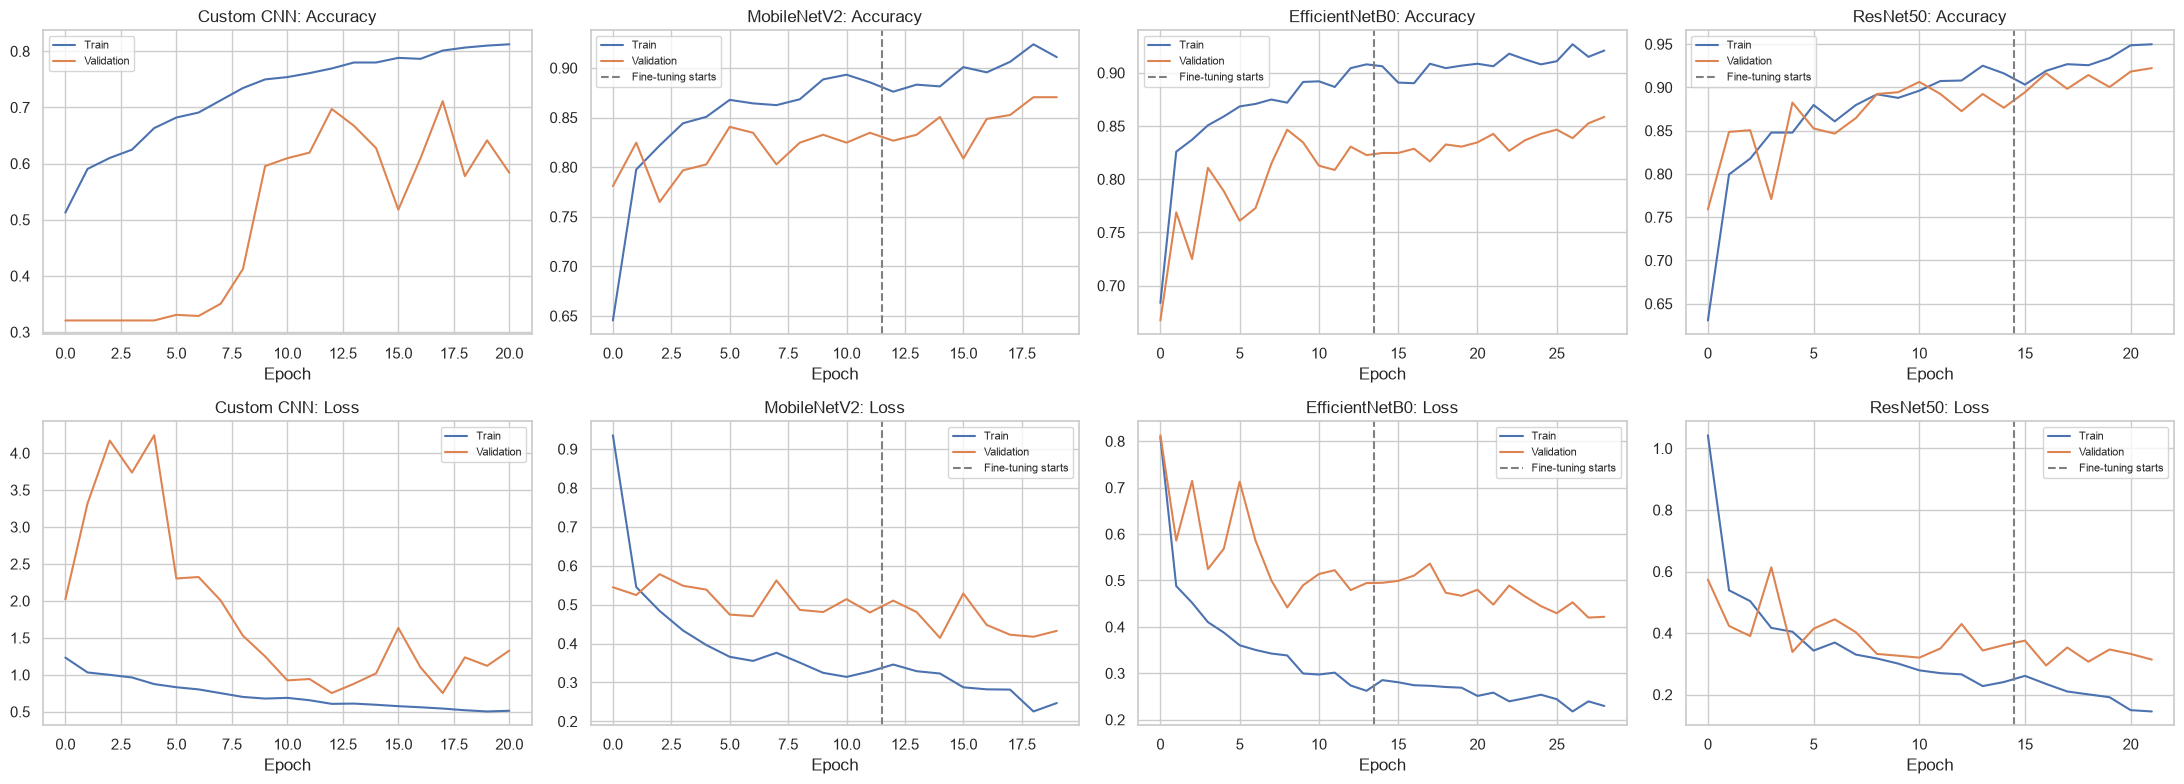

In [8]:
def load_history(name):
    if name == "Custom CNN":
        return pd.read_csv(MODELS_DIR / "custom_cnn_history.csv"), None
    h1 = pd.read_csv(MODELS_DIR / f"{name}_phase1_history.csv")
    h2 = pd.read_csv(MODELS_DIR / f"{name}_phase2_history.csv")
    return pd.concat([h1, h2], ignore_index=True), len(h1)

fig, axes = plt.subplots(2, 4, figsize=(22, 8))
for j, name in enumerate(models):
    h, split = load_history(name)
    for i, (tr, va, title) in enumerate([("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]):
        ax = axes[i, j]
        ax.plot(h[tr], label="Train"); ax.plot(h[va], label="Validation")
        if split:
            ax.axvline(split - 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
        ax.set_title(f"{name}: {title}"); ax.set_xlabel("Epoch"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_training_histories.png", dpi=150)
plt.show()

# 8: Efficiency (size, parameters, CPU speed)

In [9]:
eff_rows = []
sample = X_test[:64]
for name, m in models.items():
    m.predict(sample[:8], verbose=0)                          # warm-up
    t0 = time.perf_counter()
    m.predict(sample, batch_size=16, verbose=0)
    ms_per_img = (time.perf_counter() - t0) / len(sample) * 1000
    eff_rows.append({"Model": name,
                     "Parameters (M)": round(m.count_params() / 1e6, 2),
                     "File size (MB)": round((MODELS_DIR / MODEL_FILES[name]).stat().st_size / 1e6, 1),
                     "CPU ms/image": round(ms_per_img, 1)})

eff_df = pd.DataFrame(eff_rows).set_index("Model")
display(eff_df)

,Parameters (M),File size (MB),CPU ms/image
Model,,,
Custom CNN,1.01,12.3,54.0
MobileNetV2,2.59,26.7,40.0
EfficientNetB0,4.38,36.9,36.3
ResNet50,24.11,227.5,69.6


# 9: Final comparison table and chart

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Parameters (M),File size (MB),CPU ms/image
Model,,,,,,,,
ResNet50,0.9106,0.9139,0.9047,0.9059,0.9103,24.11,227.5,69.6
MobileNetV2,0.8333,0.8414,0.8361,0.8307,0.8330,2.59,26.7,40.0
EfficientNetB0,0.6951,0.7772,0.6714,0.6779,0.6766,4.38,36.9,36.3
Custom CNN,0.6626,0.7198,0.6720,0.6587,0.6645,1.01,12.3,54.0


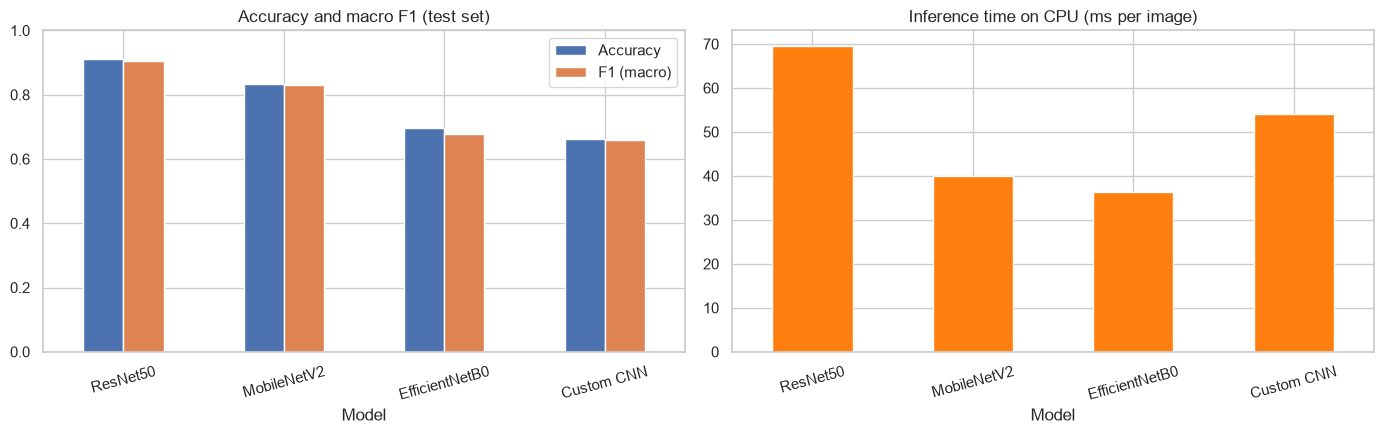

In [10]:
comparison = metrics_df.join(eff_df).sort_values("F1 (macro)", ascending=False)
display(comparison)
comparison.to_csv(FIG_DIR.parent / "model_comparison.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
comparison[["Accuracy", "F1 (macro)"]].plot(kind="bar", ax=ax[0], rot=15)
ax[0].set_title("Accuracy and macro F1 (test set)"); ax[0].set_ylim(0, 1)
comparison["CPU ms/image"].plot(kind="bar", ax=ax[1], rot=15, color="tab:orange")
ax[1].set_title("Inference time on CPU (ms per image)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_model_comparison.png", dpi=150)
plt.show()

# 10: Pick the model to deploy

In [11]:
best = comparison["F1 (macro)"].idxmax()
print("Best model by macro F1:", best)

# Slim deployment copy: no optimizer state (the loaded model was compiled with compile=False)
models[best].save(MODELS_DIR / "best_model.h5")
size_mb = round((MODELS_DIR / "best_model.h5").stat().st_size / 1e6, 1)
print(f"Saved models/best_model.h5 ({size_mb} MB)")

with open(MODELS_DIR / "best_model.json", "w") as f:
    json.dump({"model_name": best, "file": "best_model.h5",
               "class_names": CLASS_NAMES, "img_size": list(IMG_SIZE)}, f, indent=2)

if size_mb > 90:
    print("Note: close to GitHub's 100 MB file limit; we'll handle this in the GitHub phase.")

Best model by macro F1: ResNet50


Saved models/best_model.h5 (96.9 MB)
Note: close to GitHub's 100 MB file limit; we'll handle this in the GitHub phase.


#  11: Look at the mistakes of the best model

ResNet50: 22 wrong out of 246


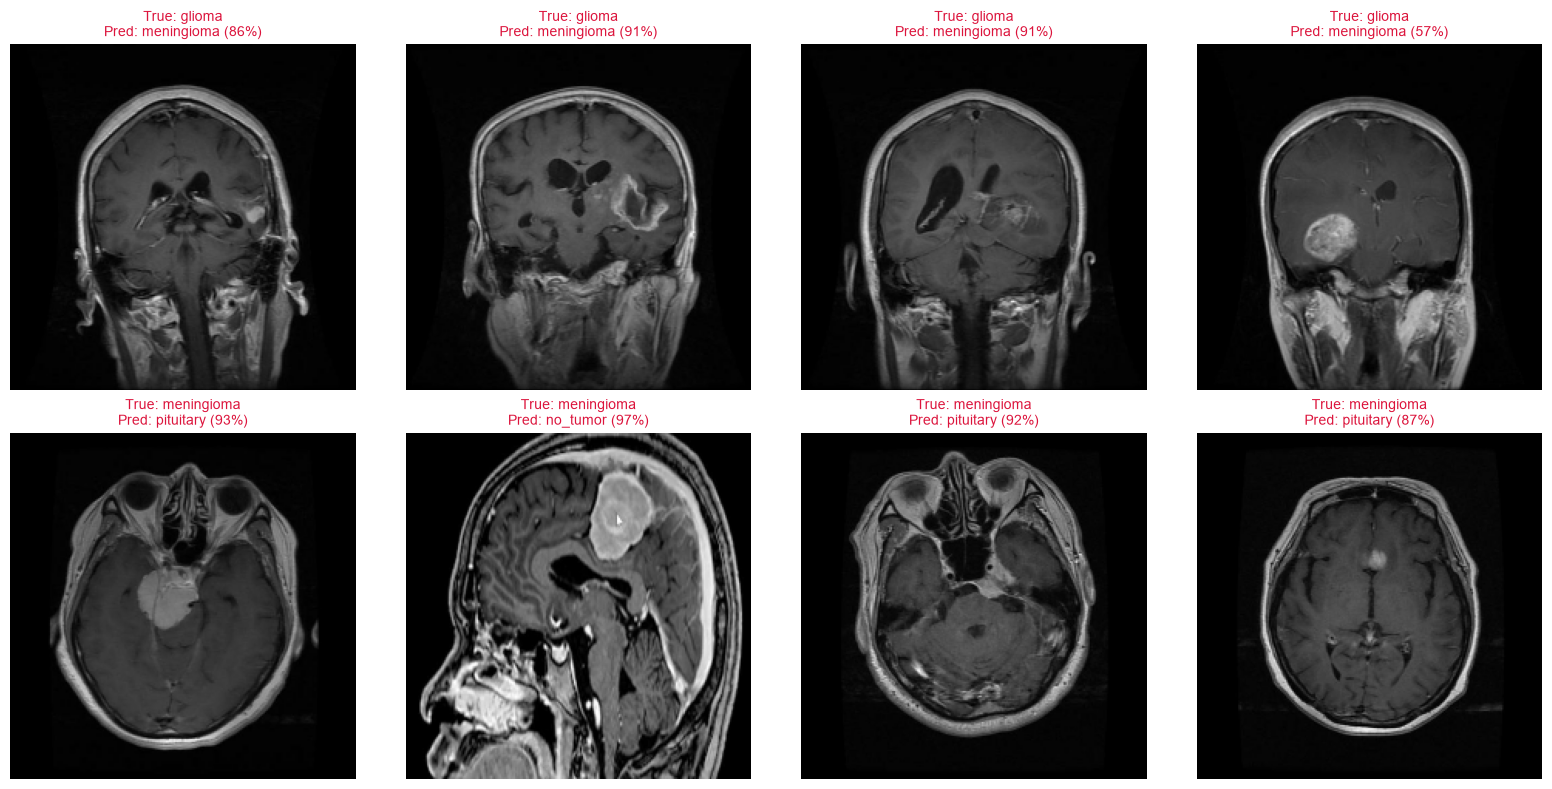

In [12]:
wrong = np.where(preds[best] != y_test)[0]
print(f"{best}: {len(wrong)} wrong out of {len(y_test)}")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong[:8]):
    ax.imshow(X_test[i])
    ax.set_title(f"True: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[preds[best][i]]} ({probs[best][i].max():.0%})",
                 fontsize=10, color="crimson")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_misclassified.png", dpi=150)
plt.show()